# Natural frequencies

The first natural angular frequencies and modes of a simply supported
rectangular isotropic plate. The stiffness and mass matrices are assembled
with `update_KC0` and `update_M`, the generalized eigenvalue problem is
solved with the dense `scipy.linalg.eigh`, and the frequencies are compared
with the closed-form natural angular frequencies of the classical plate
theory [1]. The same model is checked in `tests/test_natural_frequency.py`.

Units: N, m, kg, Pa, rad/s.

In [1]:
%matplotlib inline
import numpy as np
from scipy.sparse import coo_matrix
from scipy.linalg import eigh
import matplotlib.pyplot as plt
from composites import isotropic_plate
from structsolve import freq

from bfscplate2d import (BFSCPlate2D, update_KC0, update_M, DOF, KC0_SPARSE_SIZE,
        M_SPARSE_SIZE, DOUBLE, INT)
from bfscplate2d.quadrature import get_points_weights

## Theory

The kinetic energy and the linear strain energy give the equations of free
vibration $\boldsymbol{M}\ddot{\boldsymbol{u}} +
\boldsymbol{K}_{C0}\boldsymbol{u} = \boldsymbol{0}$, whose harmonic
solutions $\boldsymbol{u} = \boldsymbol{\phi} \sin \omega_n t$ satisfy the
generalized eigenvalue problem

$$
\boldsymbol{K}_{C0} \boldsymbol{\phi} = \omega_n^2 \boldsymbol{M}
\boldsymbol{\phi}
$$

with the natural angular frequencies $\omega_n$, in rad/s, and the modes
$\boldsymbol{\phi}$. Both matrices are symmetric and positive definite once
the rigid-body motions are constrained.

For the simply supported plate, the mode
$w = \sin(m \pi x/a) \sin(n \pi y/b)$ satisfies the equation of motion
$D \nabla^4 w = \rho h \omega^2 w$ of the classical plate theory, with the
rotary inertia neglected [1], for

$$
\omega_{mn} = \pi^2 \left( \frac{m^2}{a^2} + \frac{n^2}{b^2} \right)
\sqrt{\frac{D}{\rho h}}, \qquad D = \frac{E h^3}{12 (1 - \nu^2)}
$$

## Model

The plate of $a = 0.6$ m by $b = 0.2$ m, thickness $h = 1$ mm,
$E = 70$ GPa, $\nu = 0.3$ and $\rho = 7800$ kg/m$^3$, is meshed with 9 by 7
nodes. The mass matrix of `update_M` requires the thickness `h` and the
density `rho` of each element and no integration points.

In [2]:
nx = 9 # along x
ny = 7 # along y
points, weights = get_points_weights(nint=4)

a = 0.6
b = 0.2
E = 70e9
nu = 0.3
rho = 7.8e3
h = 0.001
lam = isotropic_plate(thickness=h, E=E, nu=nu, rho=rho)

xtmp = np.linspace(0, a, nx)
ytmp = np.linspace(0, b, ny)
xmesh, ymesh = np.meshgrid(xtmp, ytmp)

# node coordinates and position in the global matrix
ncoords = np.vstack((xmesh.T.flatten(), ymesh.T.flatten())).T
x = ncoords[:, 0]
y = ncoords[:, 1]
nids = 1 + np.arange(ncoords.shape[0])
nid_pos = dict(zip(nids, np.arange(len(nids))))
nids_mesh = nids.reshape(nx, ny)

n1s = nids_mesh[:-1, :-1].flatten()
n2s = nids_mesh[1:, :-1].flatten()
n3s = nids_mesh[1:, 1:].flatten()
n4s = nids_mesh[:-1, 1:].flatten()
num_elements = len(n1s)
print('num_elements', num_elements)

N = DOF*nx*ny
Kr = np.zeros(KC0_SPARSE_SIZE*num_elements, dtype=INT)
Kc = np.zeros(KC0_SPARSE_SIZE*num_elements, dtype=INT)
Kv = np.zeros(KC0_SPARSE_SIZE*num_elements, dtype=DOUBLE)
Mr = np.zeros(M_SPARSE_SIZE*num_elements, dtype=INT)
Mc = np.zeros(M_SPARSE_SIZE*num_elements, dtype=INT)
Mv = np.zeros(M_SPARSE_SIZE*num_elements, dtype=DOUBLE)
init_k_KC0 = 0
init_k_M = 0

for n1, n2, n3, n4 in zip(n1s, n2s, n3s, n4s):
    plate = BFSCPlate2D()
    plate.c1 = DOF*nid_pos[n1]
    plate.c2 = DOF*nid_pos[n2]
    plate.c3 = DOF*nid_pos[n3]
    plate.c4 = DOF*nid_pos[n4]
    plate.ABD = lam.ABD
    plate.h = h
    plate.rho = rho
    plate.lex = a/(nx - 1)
    plate.ley = b/(ny - 1)
    plate.init_k_KC0 = init_k_KC0
    plate.init_k_M = init_k_M
    update_KC0(plate, points, weights, Kr, Kc, Kv)
    update_M(plate, Mr, Mc, Mv)
    init_k_KC0 += KC0_SPARSE_SIZE
    init_k_M += M_SPARSE_SIZE

KC0 = coo_matrix((Kv, (Kr, Kc)), shape=(N, N)).tocsc()
M = coo_matrix((Mv, (Mr, Mc)), shape=(N, N)).tocsc()

num_elements 48


## Boundary conditions

Each node has the degrees of freedom $u$, $u_{,x}$, $u_{,y}$, $v$, $v_{,x}$,
$v_{,y}$, $w$, $w_{,x}$, $w_{,y}$, $w_{,xy}$, at the positions 0 to 9 of
`DOF = 10`. Along an edge $x$ = constant the interpolated $w$ depends only
on $w$ and $w_{,y}$ at the two nodes of the edge, so $w = 0$ on the whole
edge needs both nodal values constrained ($w$ and $w_{,x}$ on an edge $y$ =
constant); the normal slope and $w_{,xy}$ stay free, which gives the simply
supported plate. $u$ at $x = 0$ and $v$ at $y = 0$ remove the in-plane
rigid-body motions.

In [3]:
bk = np.zeros(KC0.shape[0], dtype=bool)

# simply supported: w and its derivative along the edge
edges_x = np.isclose(x, 0.) | np.isclose(x, a)
edges_y = np.isclose(y, 0.) | np.isclose(y, b)
bk[6::DOF] = edges_x | edges_y
bk[8::DOF] = edges_x
bk[7::DOF] = edges_y
# u at x = 0 and v at y = 0
bk[0::DOF] = np.isclose(x, 0.)
bk[3::DOF] = np.isclose(y, 0.)

bu = ~bk
Kuu = KC0[bu, :][:, bu]
Muu = M[bu, :][:, bu]
print('unknown degrees of freedom', bu.sum())

unknown degrees of freedom 554


## Eigenvalue problem

The first four eigenpairs of the dense symmetric pencil; the modes are
expanded back to all degrees of freedom. The same frequencies are computed
with the sparse solver `structsolve.freq`, which returns the eigenvalues
$-\omega_n^2$.

In [4]:
num_eigenvalues = 4
eigvals, eigvecsu = eigh(a=Kuu.toarray(), b=Muu.toarray(),
                         subset_by_index=(0, num_eigenvalues-1))
eigvecs = np.zeros((KC0.shape[0], num_eigenvalues), dtype=float)
eigvecs[bu, :] = eigvecsu
omegan = eigvals**0.5
print('omega_n (rad/s)', omegan)

lambda2, _ = freq(Kuu, Muu, num_eigvalues=num_eigenvalues, symmetric=True,
                  silent=True)
omegan_ss = (-lambda2)**0.5
print('structsolve.freq omega_n (rad/s)', omegan_ss)
print('max relative difference', np.max(np.abs(omegan_ss - omegan)/omegan))

omega_n (rad/s) [248.54269514 323.10727058 447.51204122 622.3822434 ]
structsolve.freq omega_n (rad/s) [248.54269504 323.10727057 447.51204113 622.38224336]
max relative difference 3.937425270493188e-10


## Comparison with the closed form

Since $a = 3b$, the lowest frequencies are those of the modes with one
half-wave along $y$, $(m, n) = (1, 1)$ to $(4, 1)$. The number of half-waves
of each computed mode along $x$ is counted from the sign changes of $w$
along the nodal line $y = b/2$.

In [5]:
D = E*h**3/(12*(1 - nu**2))
w_mid = eigvecs[6::DOF, :].reshape(nx, ny, num_eigenvalues)[:, ny//2, :]

print('%4s %7s %14s %14s %10s' % ('mode', '(m, n)', 'omega_n',
                                  'omega_mn', 'diff (%)'))
for i in range(num_eigenvalues):
    wi = w_mid[1:-1, i]
    m = 1 + np.sum(np.sign(wi[1:]) != np.sign(wi[:-1]))
    n = 1
    omega_mn = np.pi**2*(m**2/a**2 + n**2/b**2)*np.sqrt(D/(rho*h))
    print('%4d %7s %14.4f %14.4f %+10.4f' % (i + 1, '(%d, %d)' % (m, n),
          omegan[i], omega_mn, 100*(omegan[i] - omega_mn)/omega_mn))

mode  (m, n)        omega_n       omega_mn   diff (%)
   1  (1, 1)       248.5427       248.5350    +0.0031
   2  (2, 1)       323.1073       323.0956    +0.0036
   3  (3, 1)       447.5120       447.3631    +0.0333
   4  (4, 1)       622.3822       621.3376    +0.1681


The first four modes are $(m, n) = (1, 1)$ to $(4, 1)$, with natural angular
frequencies 0.0031 %, 0.0036 %, 0.033 % and 0.17 % above $\omega_{mn}$; the
difference grows with $m$, as the 8 elements along $x$ describe each
half-wave with fewer elements. `structsolve.freq` gives the same
frequencies within a relative difference of $4 \times 10^{-10}$.

## Modes

The deflection $w$ of the first four modes, at the nodes:

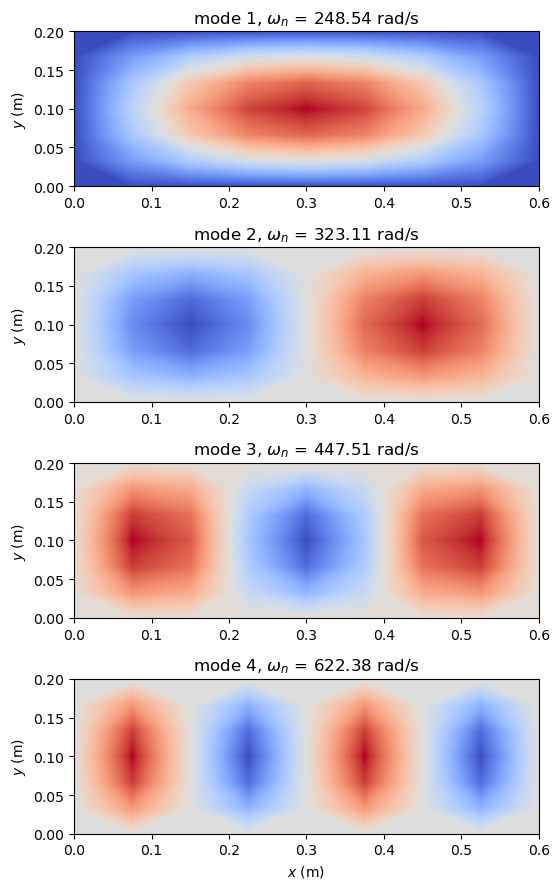

In [6]:
fig, axes = plt.subplots(num_eigenvalues, 1, figsize=(7, 9))
for i, ax in enumerate(axes):
    wplot = eigvecs[6::DOF, i].reshape(nx, ny).T
    ax.set_aspect('equal')
    levels = np.linspace(wplot.min(), wplot.max(), 300)
    ax.contourf(xmesh, ymesh, wplot, levels=levels, cmap='coolwarm')
    ax.set_title(r'mode %d, $\omega_n$ = %.2f rad/s' % (i + 1, omegan[i]))
    ax.set_ylabel('$y$ (m)')
axes[-1].set_xlabel('$x$ (m)')
fig.tight_layout()
plt.show()

## References

1. Leissa, A. W., Vibration of Plates, NASA SP-160, 1969.